SESI 1: PATTERNS OF DATA WITH ANALYSIS AND AI
Studi Kasus: Analisis Pola Curah Hujan Bengkulu Utara

Materi:
1. Descriptive Analytics
2. Diagnostic Analytics
3. Predictive Analytics
4. Prescriptive Analytics

Tujuan:
Mengolah data cuaca aktual menjadi informasi, pola, prediksi,
dan rekomendasi sederhana untuk mendukung pengambilan keputusan.


MENGAMBIL DATA CUACA AKTUAL
Berhasil: Argamakmur (1749 baris)
Berhasil: Ketahun (1749 baris)
Berhasil: Lais (1749 baris)
Berhasil: Air Napal (1749 baris)
Berhasil: Putri Hijau (1749 baris)

Sumber data:
https://open-meteo.com/en/docs/historical-weather-api

PERSIAPAN DATA
Ukuran data sebelum dibersihkan: (8745, 6)

Jumlah nilai kosong:
tanggal             0
curah_hujan_mm      0
suhu_rata_rata_c    0
lokasi              0
latitude            0
longitude           0
dtype: int64

Ukuran data setelah dibersihkan: (8745, 6)
Jumlah lokasi: 5
Tanggal awal: 2022-01-01
Tanggal akhir: 2026-10-15

Contoh data aktual:
   tanggal  curah_hujan_mm  suhu_rata_

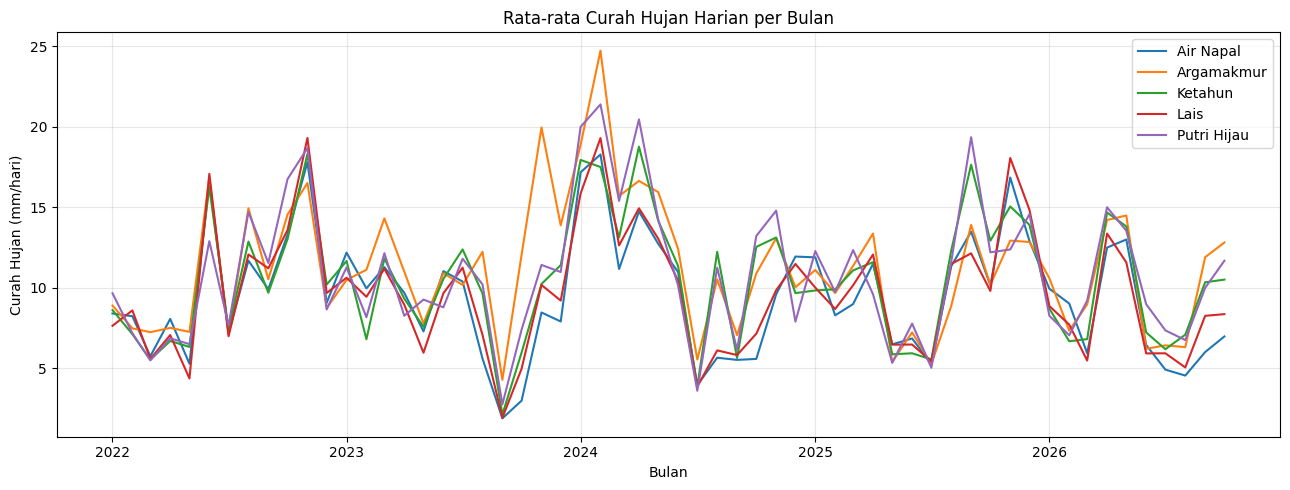


2. DIAGNOSTIC ANALYTICS

Tujuan:
Mengidentifikasi lokasi yang lebih sering mengalami
curah hujan harian tinggi berdasarkan data historis.

             hari_hujan_tinggi  jumlah_hari  maksimum_hujan_mm  persentase_hari_hujan_tinggi
lokasi                                                                                      
Ketahun                     26         1749               98.3                          1.49
Argamakmur                  25         1749              152.6                          1.43
Lais                        23         1749               87.8                          1.32
Putri Hijau                 23         1749              120.2                          1.32
Air Napal                   21         1749               75.9                          1.20

Interpretasi:
- Bandingkan frekuensi hari hujan tinggi antar lokasi.
- Periksa nilai maksimum dan grafik curah hujan.
- Hasil ini menunjukkan pola hujan, bukan penyebab banjir.


3. PREDICTIVE ANALYTICS

Tuju

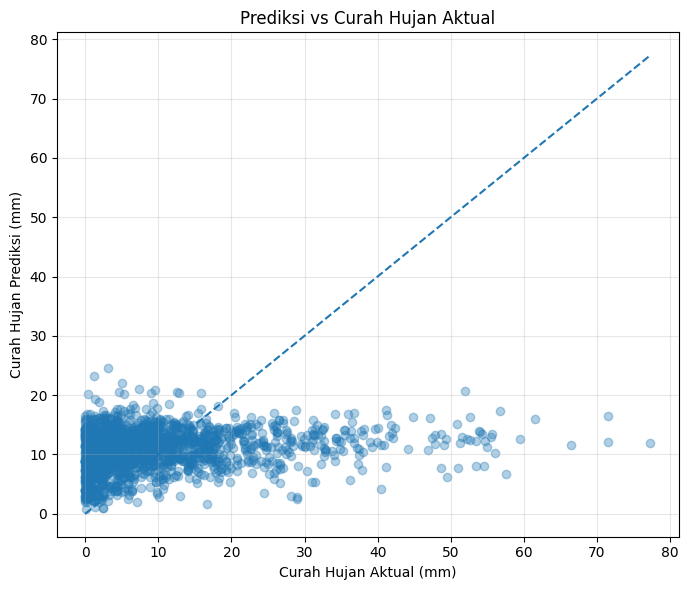


Prediksi untuk hari setelah data terakhir:
     lokasi tanggal_data_terakhir  rata_hujan_7_hari  prediksi_hujan_mm
  Air Napal            2026-10-15               6.14               2.03
 Argamakmur            2026-10-15              11.80              15.68
    Ketahun            2026-10-15               6.99               6.17
       Lais            2026-10-15               6.79               2.71
Putri Hijau            2026-10-15              10.56              11.24

4. PRESCRIPTIVE ANALYTICS

Tujuan:
Memberikan rekomendasi pemantauan sederhana berdasarkan
hasil prediksi curah hujan.


Lokasi: Argamakmur
Prediksi hujan: 15.68 mm
Kategori analisis: Pemantauan rutin
Rekomendasi: Lakukan pemantauan rutin dan ikuti informasi cuaca resmi.

Lokasi: Putri Hijau
Prediksi hujan: 11.24 mm
Kategori analisis: Pemantauan rutin
Rekomendasi: Lakukan pemantauan rutin dan ikuti informasi cuaca resmi.

Lokasi: Ketahun
Prediksi hujan: 6.17 mm
Kategori analisis: Pemantauan rutin
Rekomendasi: Lakukan 

In [ ]:
# ============================================================
# SESI 1: PATTERNS OF DATA WITH ANALYSIS AND AI
# Studi Kasus: Analisis Pola Curah Hujan Bengkulu Utara
# Sumber data aktual: Open-Meteo Historical Weather API
# ============================================================

# 1. PERSIAPAN PUSTAKA
import sys
import subprocess
import importlib.util

for package in ["requests", "pandas", "numpy", "matplotlib", "scikit-learn"]:
    module = "sklearn" if package == "scikit-learn" else package
    if importlib.util.find_spec(module) is None:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package]
        )

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import date, timedelta
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("=" * 65)
print("SESI 1: PATTERNS OF DATA WITH ANALYSIS AND AI")
print("Studi Kasus: Analisis Pola Curah Hujan Bengkulu Utara")
print("=" * 65)

print("""
Materi:
1. Descriptive Analytics
2. Diagnostic Analytics
3. Predictive Analytics
4. Prescriptive Analytics

Tujuan:
Mengolah data cuaca aktual menjadi informasi, pola, prediksi,
dan rekomendasi sederhana untuk mendukung pengambilan keputusan.
""")

# ============================================================
# 2. MENGAMBIL DATA AKTUAL
# ============================================================

# Titik koordinat perkiraan beberapa wilayah.
# Bukan batas administrasi resmi.
locations = {
    "Argamakmur": (-3.433, 102.200),
    "Ketahun": (-3.250, 101.950),
    "Lais": (-3.550, 102.150),
    "Air Napal": (-3.650, 102.200),
    "Putri Hijau": (-3.150, 101.750),
}

START_DATE = "2022-01-01"
END_DATE = (date.today() - timedelta(days=5)).isoformat()

def fetch_weather(name, coordinates):
    latitude, longitude = coordinates

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": START_DATE,
        "end_date": END_DATE,
        "daily": "precipitation_sum,temperature_2m_mean",
        "timezone": "Asia/Jakarta"
    }

    response = requests.get(url, params=params, timeout=90)
    response.raise_for_status()
    result = response.json()

    if "daily" not in result or not result["daily"].get("time"):
        raise ValueError(f"Data tidak tersedia untuk {name}")

    df = pd.DataFrame(result["daily"])

    df = df.rename(columns={
        "time": "tanggal",
        "precipitation_sum": "curah_hujan_mm",
        "temperature_2m_mean": "suhu_rata_rata_c"
    })

    df["tanggal"] = pd.to_datetime(df["tanggal"])
    df["lokasi"] = name
    df["latitude"] = latitude
    df["longitude"] = longitude

    return df

frames = []

print("\nMENGAMBIL DATA CUACA AKTUAL")

for name, coordinates in locations.items():
    try:
        result = fetch_weather(name, coordinates)
        frames.append(result)
        print(f"Berhasil: {name} ({len(result)} baris)")
    except Exception as error:
        print(f"Gagal mengambil data {name}: {error}")

if not frames:
    raise RuntimeError(
        "Data gagal diambil. Periksa koneksi internet dan coba lagi."
    )

data = pd.concat(frames, ignore_index=True)

data = data.sort_values(
    ["lokasi", "tanggal"]
).reset_index(drop=True)

print("\nSumber data:")
print("https://open-meteo.com/en/docs/historical-weather-api")

# ============================================================
# 3. PERSIAPAN DAN PEMBERSIHAN DATA
# ============================================================

print("\n" + "=" * 65)
print("PERSIAPAN DATA")
print("=" * 65)

print("Ukuran data sebelum dibersihkan:", data.shape)

print("\nJumlah nilai kosong:")
print(data.isna().sum())

data = data.dropna(
    subset=["tanggal", "lokasi", "curah_hujan_mm"]
).copy()

data = data[data["curah_hujan_mm"] >= 0].copy()

data = data.drop_duplicates(
    subset=["lokasi", "tanggal"]
)

data = data.sort_values(
    ["lokasi", "tanggal"]
).reset_index(drop=True)

if len(data) < 100:
    raise ValueError("Data aktual yang tersedia terlalu sedikit.")

print("\nUkuran data setelah dibersihkan:", data.shape)
print("Jumlah lokasi:", data["lokasi"].nunique())
print("Tanggal awal:", data["tanggal"].min().date())
print("Tanggal akhir:", data["tanggal"].max().date())

print("\nContoh data aktual:")
print(data.head(10).to_string(index=False))

# ============================================================
# SESI 1.1 — DESCRIPTIVE ANALYTICS
# ============================================================

print("\n" + "=" * 65)
print("1. DESCRIPTIVE ANALYTICS")
print("=" * 65)

print("""
Tujuan:
Merangkum data untuk mengetahui kondisi curah hujan
berdasarkan lokasi dan periode pengamatan.
""")

descriptive = data.groupby("lokasi").agg(
    jumlah_hari=("curah_hujan_mm", "count"),
    rata_rata_hujan_mm=("curah_hujan_mm", "mean"),
    maksimum_hujan_mm=("curah_hujan_mm", "max"),
    total_hujan_mm=("curah_hujan_mm", "sum"),
    rata_rata_suhu_c=("suhu_rata_rata_c", "mean")
).round(2)

print(descriptive.to_string())

# Grafik rata-rata curah hujan bulanan
monthly = (
    data.set_index("tanggal")
    .groupby("lokasi")["curah_hujan_mm"]
    .resample("MS")
    .mean()
    .reset_index()
)

plt.figure(figsize=(13, 5))

for name in monthly["lokasi"].unique():
    subset = monthly[monthly["lokasi"] == name]

    plt.plot(
        subset["tanggal"],
        subset["curah_hujan_mm"],
        label=name
    )

plt.title("Rata-rata Curah Hujan Harian per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Curah Hujan (mm/hari)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# SESI 1.2 — DIAGNOSTIC ANALYTICS
# ============================================================

print("\n" + "=" * 65)
print("2. DIAGNOSTIC ANALYTICS")
print("=" * 65)

print("""
Tujuan:
Mengidentifikasi lokasi yang lebih sering mengalami
curah hujan harian tinggi berdasarkan data historis.
""")

# Ambang analisis sederhana, bukan ambang resmi banjir.
RAIN_THRESHOLD = 50

data["hujan_tinggi"] = (
    data["curah_hujan_mm"] >= RAIN_THRESHOLD
)

diagnostic = data.groupby("lokasi").agg(
    hari_hujan_tinggi=("hujan_tinggi", "sum"),
    jumlah_hari=("hujan_tinggi", "count"),
    maksimum_hujan_mm=("curah_hujan_mm", "max")
)

diagnostic["persentase_hari_hujan_tinggi"] = (
    diagnostic["hari_hujan_tinggi"]
    / diagnostic["jumlah_hari"] * 100
).round(2)

print(diagnostic.sort_values(
    "hari_hujan_tinggi",
    ascending=False
).to_string())

print("""
Interpretasi:
- Bandingkan frekuensi hari hujan tinggi antar lokasi.
- Periksa nilai maksimum dan grafik curah hujan.
- Hasil ini menunjukkan pola hujan, bukan penyebab banjir.
""")

# ============================================================
# SESI 1.3 — PREDICTIVE ANALYTICS
# ============================================================

print("\n" + "=" * 65)
print("3. PREDICTIVE ANALYTICS")
print("=" * 65)

print("""
Tujuan:
Membangun model Machine Learning Random Forest Regression
untuk memperkirakan curah hujan pada hari berikutnya.
""")

model_data = data[
    ["tanggal", "lokasi", "curah_hujan_mm"]
].copy()

# Membuat fitur dari data historis sebelumnya.
for lag in [1, 2, 3, 7]:
    model_data[f"hujan_lag_{lag}"] = (
        model_data.groupby("lokasi")["curah_hujan_mm"]
        .shift(lag)
    )

model_data["rata_hujan_7_hari"] = (
    model_data.groupby("lokasi")["curah_hujan_mm"]
    .transform(
        lambda s: s.shift(1).rolling(
            7, min_periods=7
        ).mean()
    )
)

# Target adalah pengamatan curah hujan pada hari berikutnya.
model_data["target_hujan_berikutnya"] = (
    model_data.groupby("lokasi")["curah_hujan_mm"]
    .shift(-1)
)

features = [
    "hujan_lag_1",
    "hujan_lag_2",
    "hujan_lag_3",
    "hujan_lag_7",
    "rata_hujan_7_hari",
    "lokasi"
]

model_data = model_data.dropna(
    subset=features + ["target_hujan_berikutnya"]
).copy()

if len(model_data) < 100:
    raise ValueError("Data tidak cukup untuk melatih model.")

# Membagi data berdasarkan waktu, bukan secara acak.
unique_dates = np.sort(model_data["tanggal"].unique())

cutoff = int(len(unique_dates) * 0.8)
cutoff = min(max(cutoff, 1), len(unique_dates) - 1)

cutoff_date = pd.Timestamp(unique_dates[cutoff])

train = model_data[
    model_data["tanggal"] < cutoff_date
].copy()

test = model_data[
    model_data["tanggal"] >= cutoff_date
].copy()

X_train = train[features]
y_train = train["target_hujan_berikutnya"]

X_test = test[features]
y_test = test["target_hujan_berikutnya"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "lokasi",
            OneHotEncoder(handle_unknown="ignore"),
            ["lokasi"]
        )
    ],
    remainder="passthrough"
)

model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

predictions = np.maximum(
    0,
    model.predict(X_test)
)

mae = mean_absolute_error(
    y_test,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predictions
    )
)

print("Jumlah data latih:", len(train))
print("Jumlah data uji:", len(test))
print("Awal periode pengujian:", cutoff_date.date())
print(f"MAE  : {mae:.2f} mm")
print(f"RMSE : {rmse:.2f} mm")

# Grafik prediksi dibandingkan pengamatan aktual.
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.35
)

maximum = max(
    float(y_test.max()),
    float(predictions.max()),
    1
)

plt.plot(
    [0, maximum],
    [0, maximum],
    linestyle="--"
)

plt.title("Prediksi vs Curah Hujan Aktual")
plt.xlabel("Curah Hujan Aktual (mm)")
plt.ylabel("Curah Hujan Prediksi (mm)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Membuat prediksi berdasarkan data terakhir setiap lokasi.
latest_features = []

for name, subset in data.groupby("lokasi"):
    subset = subset.sort_values("tanggal")
    rain = subset["curah_hujan_mm"].to_numpy()

    if len(rain) < 7:
        continue

    latest_features.append({
        "lokasi": name,
        "tanggal_data_terakhir": subset["tanggal"].max(),
        "hujan_lag_1": rain[-1],
        "hujan_lag_2": rain[-2],
        "hujan_lag_3": rain[-3],
        "hujan_lag_7": rain[-7],
        "rata_hujan_7_hari": np.mean(rain[-7:])
    })

latest = pd.DataFrame(latest_features)

if latest.empty:
    raise ValueError("Tidak cukup data terbaru untuk membuat prediksi.")

latest["prediksi_hujan_mm"] = np.maximum(
    0,
    model.predict(latest[features])
)

print("\nPrediksi untuk hari setelah data terakhir:")
print(latest[[
    "lokasi",
    "tanggal_data_terakhir",
    "rata_hujan_7_hari",
    "prediksi_hujan_mm"
]].round(2).to_string(index=False))

# ============================================================
# SESI 1.4 — PRESCRIPTIVE ANALYTICS
# ============================================================

print("\n" + "=" * 65)
print("4. PRESCRIPTIVE ANALYTICS")
print("=" * 65)

print("""
Tujuan:
Memberikan rekomendasi pemantauan sederhana berdasarkan
hasil prediksi curah hujan.
""")

def interpret_rain(value):
    if value >= 50:
        return "Indikasi hujan tinggi"
    elif value >= 20:
        return "Perlu pemantauan"
    return "Pemantauan rutin"

latest["interpretasi"] = (
    latest["prediksi_hujan_mm"].apply(interpret_rain)
)

for _, row in latest.sort_values(
    "prediksi_hujan_mm",
    ascending=False
).iterrows():

    value = row["prediksi_hujan_mm"]
    name = row["lokasi"]

    if value >= 50:
        recommendation = (
            "Periksa informasi resmi BMKG/BPBD dan tingkatkan "
            "pemantauan kondisi lingkungan."
        )
    elif value >= 20:
        recommendation = (
            "Pantau prakiraan cuaca resmi dan periksa saluran "
            "drainase di lingkungan setempat."
        )
    else:
        recommendation = (
            "Lakukan pemantauan rutin dan ikuti informasi cuaca resmi."
        )

    print(f"\nLokasi: {name}")
    print(f"Prediksi hujan: {value:.2f} mm")
    print(f"Kategori analisis: {row['interpretasi']}")
    print(f"Rekomendasi: {recommendation}")

# ============================================================
# 5. KESIMPULAN
# ============================================================

print("\n" + "=" * 65)
print("KESIMPULAN SESI 1")
print("=" * 65)

highest = latest.loc[
    latest["prediksi_hujan_mm"].idxmax()
]

print(
    "Lokasi dengan prediksi curah hujan tertinggi di antara "
    f"lokasi yang berhasil dianalisis: {highest['lokasi']}."
)

print(
    "Prediksi curah hujan: "
    f"{highest['prediksi_hujan_mm']:.2f} mm."
)

print("""
Studi kasus ini menerapkan empat tingkatan analitik:
deskriptif, diagnostik, prediktif, dan preskriptif.
Data aktual diolah menjadi informasi dan rekomendasi sederhana.

Catatan:
- Prediksi model bukan prakiraan cuaca resmi.
- Ambang hujan yang digunakan bukan ambang resmi banjir.
- Hasil perlu dibandingkan dengan informasi resmi BMKG.
- Data yang digunakan merupakan data historis dari Open-Meteo.

Sumber:
https://open-meteo.com/en/docs/historical-weather-api
""")